# Baku Pharmacy Chain — Market Basket Analysis & Cross-Sell Recommender
**Daily Data Analytics Project · Day 09**

## Business question
*A 6-store Baku pharmacy chain wants to raise basket value without discounting. **Which products are genuinely bought together, which only look related because of the season, which are substitutes, and how much could a pharmacist prompt / shelf placement / POS recommender earn?***

Approach:
1. Clean point-of-sale lines (returns, double scans).
2. Basket KPIs and EDA (basket size, top products, seasonality).
3. **Apriori implemented from scratch** (NumPy) → association rules with support, confidence, lift, leverage, conviction, and a **χ² test with Benjamini–Hochberg FDR** so we only act on rules that are not noise.
4. Separate **true substitutes** from **seasonal artefacts** with a month-stratified lift.
5. A rule-based **recommender**, trained on Jan–Jul and tested on Aug–Sep with a hide-one-item protocol against a popularity baseline.
6. Size the cross-sell opportunity in AZN (OTC only — prescription drugs are never prompted).

> Data is **synthetic** (fixed seed), generated by `data/generate_data.py`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import PercentFormatter
import basket as mb
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 80)
products, baskets, raw_lines = mb.load_raw()
NAME = dict(zip(products.product_id, products.product_name))
CAT = dict(zip(products.product_id, products.category))
RX = set(products.loc[products.is_rx == 1, "product_id"])
print(products.shape, baskets.shape, raw_lines.shape)
raw_lines.head()

(49, 5) (47866, 4) (117472, 4)


,basket_id,product_id,qty,unit_price
0,B019950,P20,1,5.900
1,B002094,P45,1,4.900
2,B040327,P19,1,6.600
3,B040449,P40,1,3.500
4,B016222,P34,1,11.200


## 1. Data quality check

In [2]:
lines, log = mb.clean(raw_lines)
checks = {
 **log,
 "Duplicate basket_id in baskets": int(baskets.basket_id.duplicated().sum()),
 "Lines with unknown basket_id": int((~raw_lines.basket_id.isin(baskets.basket_id)).sum()),
 "Lines with unknown product_id": int((~raw_lines.product_id.isin(products.product_id)).sum()),
 "Baskets with no clean lines": int((~baskets.basket_id.isin(lines.basket_id)).sum()),
 "Date range": f"{baskets.ts.min():%Y-%m-%d} → {baskets.ts.max():%Y-%m-%d}",
 "Missing values (all tables)": int(products.isna().sum().sum() + baskets.isna().sum().sum() + raw_lines.isna().sum().sum()),
}
pp = lines.merge(products[["product_id", "list_price"]], on="product_id")
checks["Unit price ≠ list price (promo lines)"] = f"{(~np.isclose(pp.unit_price, pp.list_price)).mean():.1%}"
checks["Unit price outside 85–100% of list"] = int((~(pp.unit_price / pp.list_price).between(0.85, 1.0001)).sum())
pd.Series(checks).to_frame("result")

,result
Raw lines,117472
Return lines (qty < 0) removed,180
Exact duplicate lines removed,95
Clean lines,117197
Duplicate basket_id in baskets,0
Lines with unknown basket_id,0
Lines with unknown product_id,0
Baskets with no clean lines,0
Date range,2026-01-01 → 2026-09-30
Missing values (all tables),0


Returns (negative quantities) and double-scanned lines are removed; after cleaning every product appears at most once per basket, which is what market basket analysis needs (presence, not quantity). About 8% of lines carry a 10% promo price — expected, not an error.

## 2. Headline KPIs

In [3]:
bk = (lines.groupby("basket_id").agg(items=("product_id", "nunique"), revenue=("revenue", "sum"))
        .join(baskets.set_index("basket_id")))
bk["month"] = bk.ts.dt.to_period("M")
K = {
 "Baskets": f"{len(bk):,}",
 "Revenue, AZN": f"{bk.revenue.sum():,.0f}",
 "Average basket value, AZN": f"{bk.revenue.mean():.2f}",
 "Distinct products per basket": f"{bk['items'].mean():.2f}",
 "Single-item baskets": f"{(bk['items'] == 1).mean():.1%}",
 "Baskets with a prescription (Rx) item": f"{bk.index.isin(lines.loc[lines.product_id.isin(RX), 'basket_id']).mean():.1%}",
 "Loyalty-card baskets": f"{bk.loyalty_card.mean():.1%}",
}
pd.Series(K).to_frame("value")

,value
Baskets,"47,866"
"Revenue, AZN","937,096"
"Average basket value, AZN",19.58
Distinct products per basket,2.45
Single-item baskets,30.3%
Baskets with a prescription (Rx) item,22.1%
Loyalty-card baskets,37.9%


In [4]:
by_items = bk.groupby(bk['items'].clip(upper=5)).agg(baskets=("revenue", "size"), avg_value=("revenue", "mean"))
by_items.index = by_items.index.map(lambda x: "5+" if x == 5 else str(x))
by_items["share"] = by_items.baskets / by_items.baskets.sum()
by_items

,baskets,avg_value,share
items,,,
1,14504,6.954,0.303
2,14422,16.564,0.301
3,9373,24.545,0.196
4,5079,32.176,0.106
5+,4488,45.426,0.094


Every extra product in a basket adds roughly its own price to the ticket — so turning single-item baskets into two-item baskets is the main revenue lever. That is exactly what a cross-sell programme targets.

## 3. Exploratory analysis

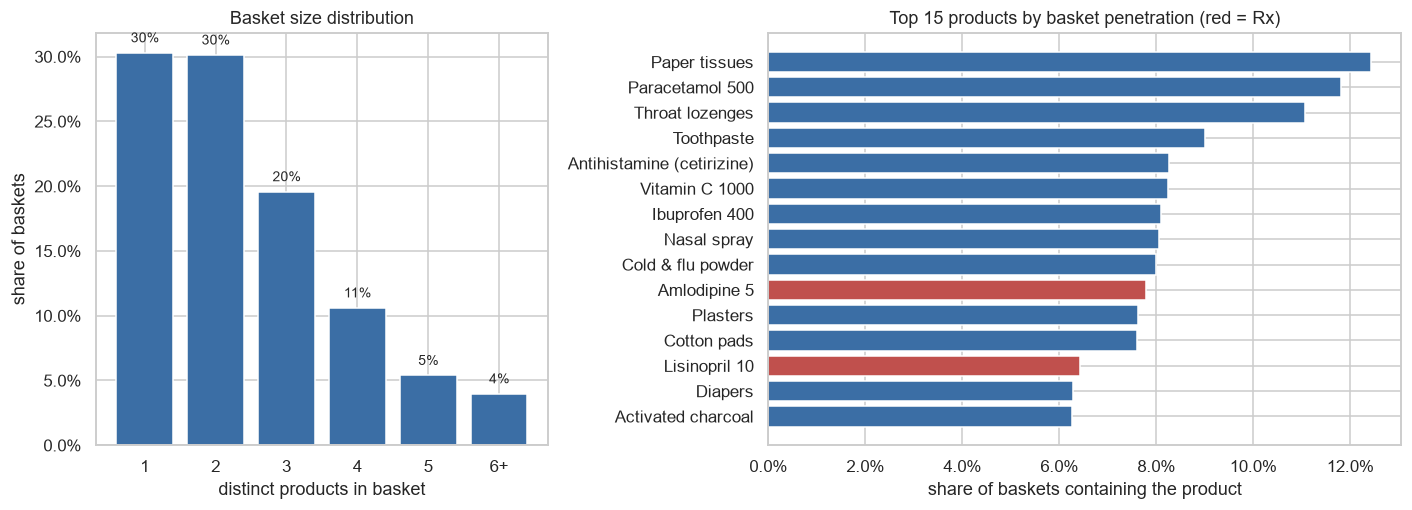

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
s = bk['items'].clip(upper=6).value_counts(normalize=True).sort_index()
ax[0].bar([str(i) if i < 6 else "6+" for i in s.index], s.values, color="#3b6ea5")
ax[0].yaxis.set_major_formatter(PercentFormatter(1))
ax[0].set(title="Basket size distribution", xlabel="distinct products in basket", ylabel="share of baskets")
for i, v in enumerate(s.values): ax[0].text(i, v + 0.008, f"{v:.0%}", ha="center", fontsize=9)
top = (lines.groupby("product_id").basket_id.nunique() / len(bk)).sort_values().tail(15)
ax[1].barh([NAME[p] for p in top.index], top.values,
           color=["#c0504d" if p in RX else "#3b6ea5" for p in top.index])
ax[1].xaxis.set_major_formatter(PercentFormatter(1))
ax[1].set(title="Top 15 products by basket penetration (red = Rx)", xlabel="share of baskets containing the product")
plt.tight_layout(); plt.savefig("images/eda_overview.png", bbox_inches="tight"); plt.show()

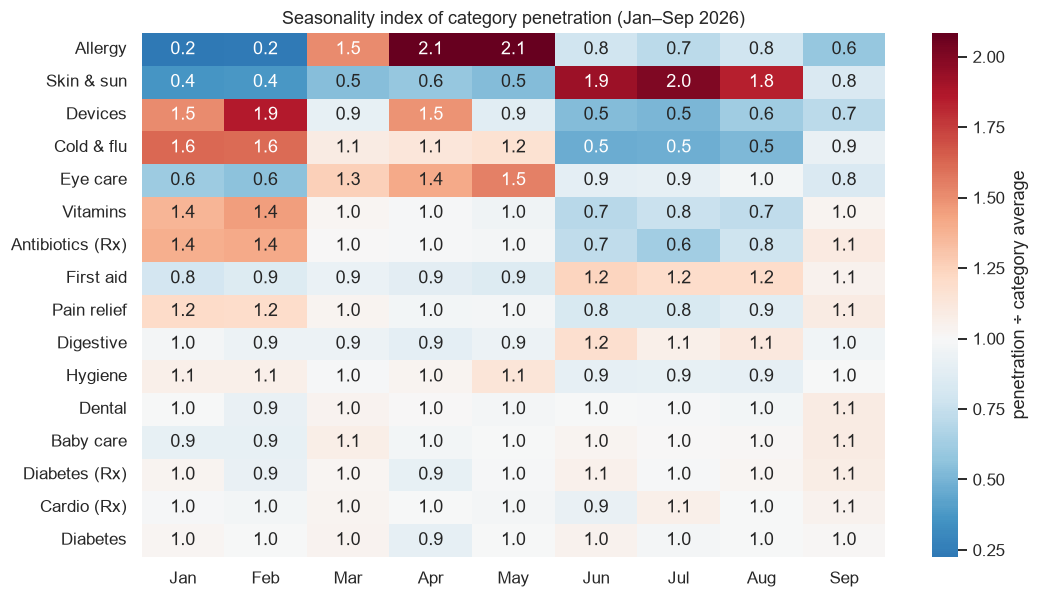

In [6]:
cat_month = (lines.merge(baskets[["basket_id", "ts"]], on="basket_id")
               .assign(category=lambda d: d.product_id.map(CAT), month=lambda d: d.ts.dt.strftime("%b")))
pen = cat_month.groupby(["category", "month"]).basket_id.nunique().unstack()
pen = pen[pd.date_range("2026-01-01", periods=9, freq="MS").strftime("%b")]
pen = pen.div(bk.groupby(bk.ts.dt.strftime("%b")).size()[pen.columns], axis=1)
idx = pen.div(pen.mean(axis=1), axis=0)                      # seasonality index (1 = category average)
idx = idx.loc[idx.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 5.6))
sns.heatmap(idx, cmap="RdBu_r", center=1, annot=True, fmt=".1f", cbar_kws={"label": "penetration ÷ category average"}, ax=ax)
ax.set(title="Seasonality index of category penetration (Jan–Sep 2026)", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig("images/seasonality.png", bbox_inches="tight"); plt.show()

Cold & flu peaks in Jan–Feb, allergy in Apr–May and skin & sun in Jun–Aug. Any rule that pairs products from different seasons will show **lift < 1** even if customers do not see them as substitutes — we check for this in section 6.

## 4. Apriori → association rules
Apriori is implemented in `basket.py` (level-wise candidate generation + subset pruning, support counted with vectorised NumPy). Metrics for a rule A → B:

| metric | formula | reading |
|---|---|---|
| support | P(A∧B) | how common the pair is |
| confidence | P(B\|A) | hit rate of the prompt |
| lift | P(B\|A) / P(B) | > 1 = bought together more than chance |
| leverage | P(A∧B) − P(A)P(B) | extra co-occurrences in absolute terms |
| conviction | (1 − P(B)) / (1 − conf) | how often the rule would be wrong if A and B were independent |

Each rule also gets a 2×2 **χ² test**; with hundreds of rules we control the false-discovery rate with **Benjamini–Hochberg**.

In [7]:
X = mb.one_hot(lines)
MIN_SUP = 0.003   # ≈ 145 baskets
freq = mb.apriori(X, min_support=MIN_SUP, max_len=3)
print(f"{X.shape[0]:,} baskets × {X.shape[1]} products → {len(freq)} frequent itemsets", freq["size"].value_counts().sort_index().to_dict())
R = mb.label(mb.rules(freq, len(X)), NAME)
strong = R[(R.q_value < 0.01) & (R.lift >= 1.5) & (R.confidence >= 0.20)].copy()
print(f"{len(R)} rules generated; {len(strong)} pass q < 0.01, lift ≥ 1.5, confidence ≥ 20%")
# keep one direction per pair, preferring the higher-confidence direction
strong["key"] = [frozenset(a + c) for a, c in zip(strong.antecedent, strong.consequent)]
top_rules = strong.sort_values("confidence", ascending=False).drop_duplicates("key").sort_values("lift", ascending=False)
top_rules[["rule", "support", "confidence", "lift", "leverage", "conviction", "q_value"]].head(20)

47,866 baskets × 49 products → 308 frequent itemsets {1: 49, 2: 190, 3: 69}
794 rules generated; 326 pass q < 0.01, lift ≥ 1.5, confidence ≥ 20%


,rule,support,confidence,lift,leverage,conviction,q_value
1,Lancets → Metformin 850,0.020,0.863,17.866,0.019,6.964,0.000
3,Glucose test strips + Lancets → Metformin 850,0.011,0.855,17.688,0.010,6.551,0.000
6,Glucose test strips → Metformin 850,0.026,0.850,17.592,0.024,6.349,0.000
9,Lancets → Glucose test strips,0.012,0.536,17.552,0.012,2.088,0.000
14,Insect repellent → After-sun gel,0.008,0.381,14.468,0.008,1.573,0.000
23,Elastic bandage → Antiseptic solution,0.008,0.495,13.444,0.007,1.909,0.000
24,Insect repellent → Sunscreen SPF50,0.017,0.810,13.395,0.016,4.955,0.000
29,After-sun gel + Insect repellent → Sunscreen SPF50,0.006,0.796,13.163,0.006,4.614,0.000
30,After-sun gel → Sunscreen SPF50,0.021,0.796,13.160,0.019,4.610,0.000
36,Infant formula → Baby wipes,0.023,0.565,11.240,0.021,2.184,0.000


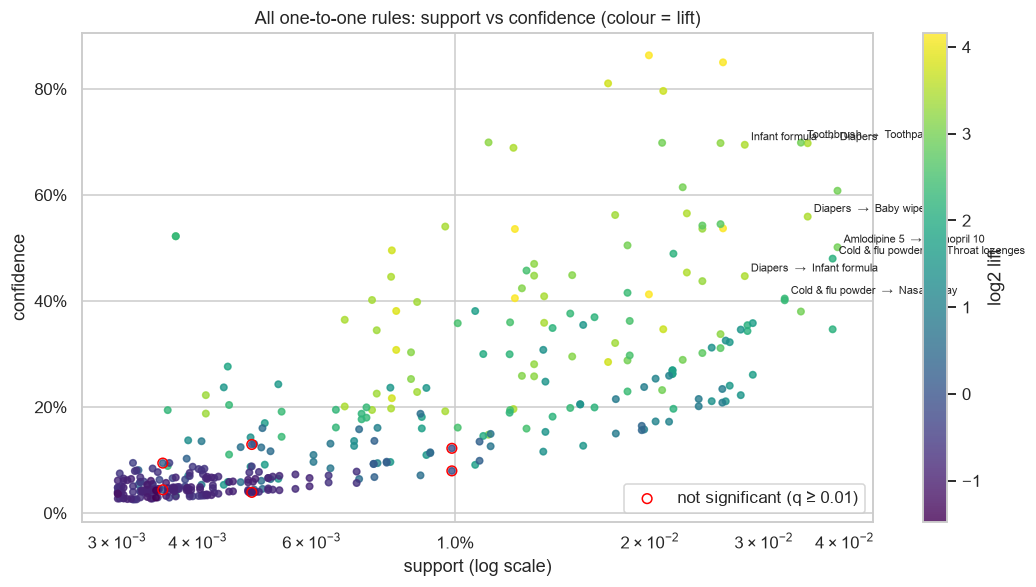

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5))
pairs = R[(R.antecedent.map(len) == 1) & (R.consequent.map(len) == 1)]
sc = ax.scatter(pairs.support, pairs.confidence, c=np.log2(pairs.lift), cmap="viridis", s=18, alpha=.8)
sig = pairs.q_value >= 0.01
ax.scatter(pairs.support[sig], pairs.confidence[sig], facecolors="none", edgecolors="red", s=40, label="not significant (q ≥ 0.01)")
plt.colorbar(sc, label="log2 lift")
ax.set_xscale("log"); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
for _, r in pairs.sort_values("leverage", ascending=False).drop_duplicates("chi2").head(7).iterrows():
    ax.annotate(r.rule, (r.support, r.confidence), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.set(title="All one-to-one rules: support vs confidence (colour = lift)", xlabel="support (log scale)", ylabel="confidence")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig("images/rules_scatter.png", bbox_inches="tight"); plt.show()

## 5. Rule network — which products form 'missions'?

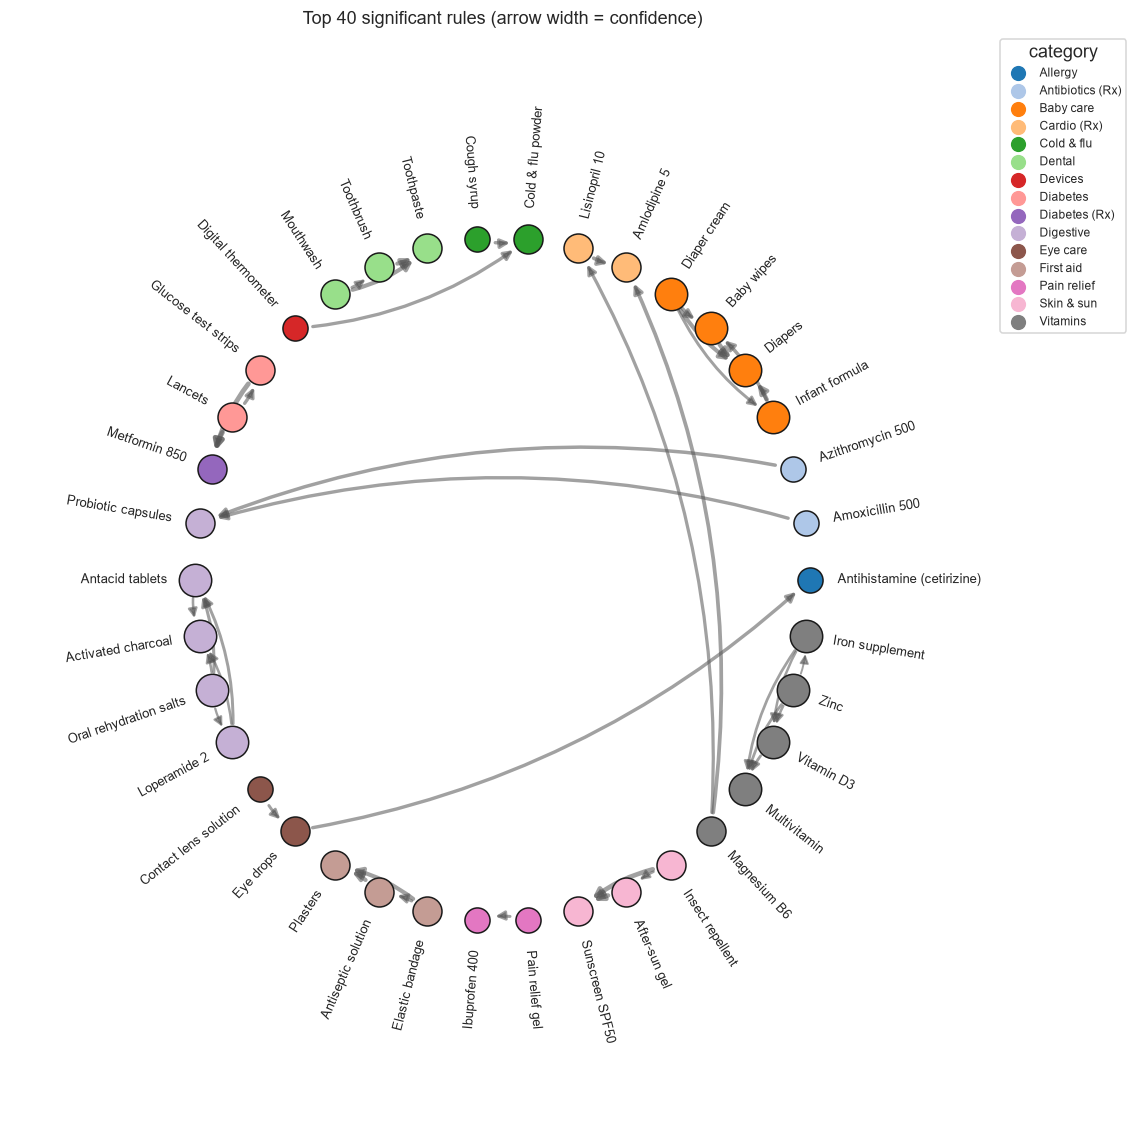

In [9]:
edges = top_rules[(top_rules.antecedent.map(len) == 1) & (top_rules.consequent.map(len) == 1)].head(40)
nodes = sorted(set(edges.antecedent.str[0]) | set(edges.consequent.str[0]), key=lambda p: (CAT[p], p))
cats = sorted(set(CAT[p] for p in nodes))
pal = dict(zip(cats, sns.color_palette("tab20", len(cats))))
theta = np.linspace(0, 2 * np.pi, len(nodes), endpoint=False)
pos = {p: (np.cos(t), np.sin(t)) for p, t in zip(nodes, theta)}
fig, ax = plt.subplots(figsize=(10.5, 10.5))
for _, e in edges.iterrows():
    (x1, y1), (x2, y2) = pos[e.antecedent[0]], pos[e.consequent[0]]
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", lw=0.6 + 3 * e.confidence,
                alpha=.55, color="#555", connectionstyle="arc3,rad=0.15", shrinkA=12, shrinkB=12))
deg = pd.concat([edges.antecedent.str[0], edges.consequent.str[0]]).value_counts()
for p, t in zip(nodes, theta):
    x, y = pos[p]
    ax.scatter(x, y, s=180 + 90 * deg[p], color=pal[CAT[p]], edgecolor="k", zorder=3)
    left = np.cos(t) < 0                                  # radial labels, flipped on the left half
    ax.text(1.09 * x, 1.09 * y, NAME[p], ha="right" if left else "left", va="center", fontsize=8.5,
            rotation=np.degrees(t) + (180 if left else 0), rotation_mode="anchor")
for c in cats: ax.scatter([], [], color=pal[c], label=c, s=80)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), title="category", fontsize=8)
ax.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), title="Top 40 significant rules (arrow width = confidence)"); ax.axis("off")
plt.tight_layout(); plt.savefig("images/rule_network.png", bbox_inches="tight"); plt.show()

The graph splits into clear clusters — diabetes care, sun season, first aid, baby care, dental, cold & flu, antibiotic + probiotic, cardio + supplements — i.e. customer *missions*. Cross-category bridges (antibiotic → probiotic, blood-pressure meds → Magnesium B6) are the most valuable prompts because shoppers would not find them by browsing a single shelf.

## 6. Substitutes or seasonal artefacts?
A raw lift < 1 can have three causes:
1. **substitutes** — one product replaces the other (two painkillers, two antibiotics);
2. **seasonality** — the products sell in different months (cold remedies vs sunscreen);
3. **small baskets** — with ~2.5 products per basket, a shopper on one mission rarely buys from another, so *unrelated* products also sit below lift 1.

We remove (2) by computing lift **stratified by month** (expectation built inside each month), and handle (3) by comparing with the **median stratified lift of unrelated cross-category pairs** instead of with 1. A pair is called a **substitute** only if it is far below that baseline (< ½) **and** both products serve the same need (same category); far-below pairs from different categories are simply *different missions*.

In [10]:
PL = mb.pair_lift(X).merge(mb.stratified_pair_lift(X, baskets.set_index("basket_id").ts.dt.month), on=["a", "b"])
cross = PL[(PL.a.map(CAT) != PL.b.map(CAT)) & (PL.expected >= 40)]
BASE = cross.strat_lift.median()
print(f"Median month-stratified lift of unrelated cross-category pairs: {BASE:.2f} (this, not 1.0, is the 'no relationship' level)")
neg = PL[PL.expected >= 40].sort_values("lift").head(10).copy()
neg["season_explains"] = (neg.strat_lift - neg.lift) / (BASE - neg.lift)          # share of the gap to baseline closed by stratifying
neg["pair"] = neg.a.map(NAME) + "  ×  " + neg.b.map(NAME)
same_cat = neg.a.map(CAT) == neg.b.map(CAT)
far_below = neg.strat_lift < 0.5 * BASE
neg["verdict"] = np.select([far_below & same_cat, far_below], ["substitute", "different missions (not substitutes)"],
                           "seasonal + small-basket effect")
neg[["pair", "observed", "expected", "lift", "strat_lift", "season_explains", "verdict"]]

Median month-stratified lift of unrelated cross-category pairs: 0.51 (this, not 1.0, is the 'no relationship' level)


,pair,observed,expected,lift,strat_lift,season_explains,verdict
473,Amoxicillin 500 × Azithromycin 500,0.000,67.663,0.000,0.000,0.000,substitute
31,Cold & flu powder × Insect repellent,7.000,81.328,0.086,0.228,0.338,different missions (not substitutes)
316,Ibuprofen 400 × Metamizole 500,16.000,145.234,0.110,0.110,-0.001,substitute
169,Cough syrup × Insect repellent,6.000,45.258,0.133,0.357,0.602,seasonal + small-basket effect
29,Cold & flu powder × Sunscreen SPF50,31.000,231.361,0.134,0.322,0.505,seasonal + small-basket effect
167,Cough syrup × Sunscreen SPF50,19.000,128.749,0.148,0.359,0.591,seasonal + small-basket effect
30,Cold & flu powder × After-sun gel,16.000,100.741,0.159,0.419,0.750,seasonal + small-basket effect
168,Cough syrup × After-sun gel,9.000,56.061,0.161,0.430,0.780,seasonal + small-basket effect
521,Azithromycin 500 × Glucose test strips,9.000,45.937,0.196,0.195,-0.003,different missions (not substitutes)
213,Vitamin C 1000 × Insect repellent,17.000,83.944,0.203,0.338,0.445,seasonal + small-basket effect


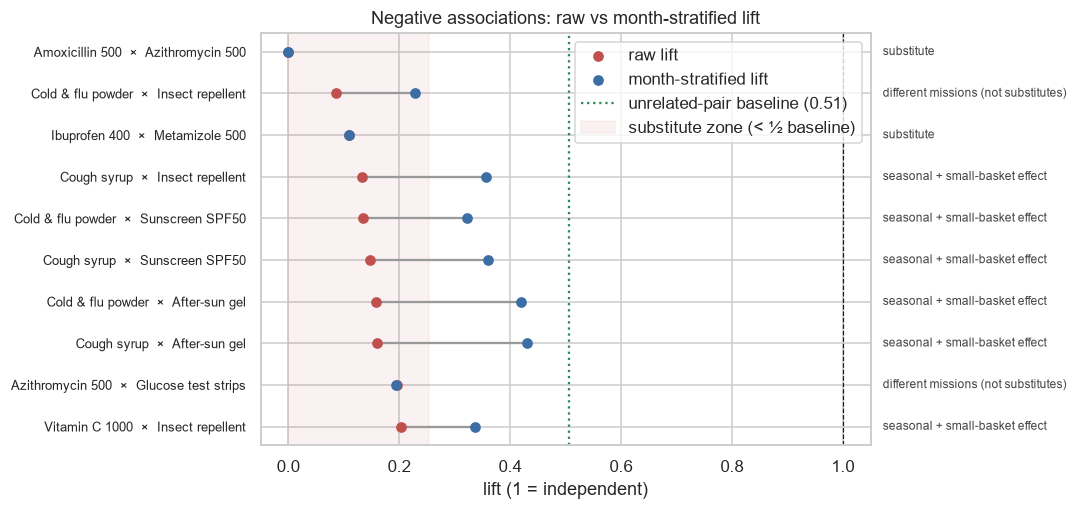

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(neg))
ax.hlines(y, neg.lift, neg.strat_lift, color="#999")
ax.scatter(neg.lift, y, color="#c0504d", label="raw lift", zorder=3)
for yy, v in zip(y, neg.verdict): ax.text(1.02, yy, v, va="center", fontsize=8, color="#444", transform=ax.get_yaxis_transform())
ax.scatter(neg.strat_lift, y, color="#3b6ea5", label="month-stratified lift", zorder=3)
ax.axvline(1, ls="--", color="k", lw=.8); ax.axvline(BASE, ls=":", color="#2e8b57", lw=1.5, label=f"unrelated-pair baseline ({BASE:.2f})")
ax.axvspan(0, 0.5 * BASE, color="#c0504d", alpha=.07, label="substitute zone (< ½ baseline)")
ax.set_yticks(y, neg.pair, fontsize=8.5); ax.invert_yaxis()
ax.set(title="Negative associations: raw vs month-stratified lift", xlabel="lift (1 = independent)")
ax.legend(); plt.tight_layout(); plt.savefig("images/substitutes.png", bbox_inches="tight"); plt.show()

## 7. Rule strength through the year

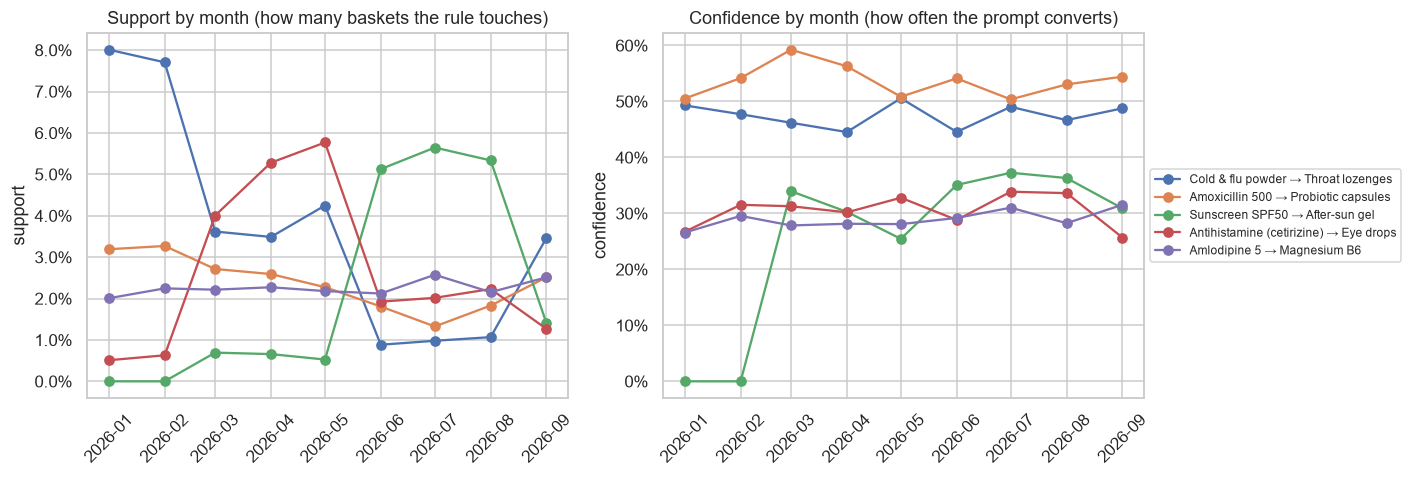

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep
rule,,,,,,,,,
Cold & flu powder → Throat lozenges,0.080,0.077,0.036,0.035,0.042,0.009,0.010,0.011,0.035
Amoxicillin 500 → Probiotic capsules,0.032,0.033,0.027,0.026,0.023,0.018,0.013,0.018,0.025
Sunscreen SPF50 → After-sun gel,0.000,0.000,0.007,0.007,0.005,0.051,0.056,0.053,0.014
Antihistamine (cetirizine) → Eye drops,0.005,0.006,0.040,0.053,0.058,0.019,0.020,0.022,0.013
Amlodipine 5 → Magnesium B6,0.020,0.022,0.022,0.023,0.022,0.021,0.026,0.022,0.025


In [12]:
watch = [("P01", "P02"), ("P12", "P14"), ("P31", "P32"), ("P45", "P44"), ("P19", "P22")]
bm = baskets.set_index("basket_id").ts.dt.to_period("M").reindex(X.index)
rows = []
for a, b in watch:
    for m, g in X[[a, b]].groupby(bm):
        n_a = g[a].sum(); n_ab = (g[a] & g[b]).sum()
        rows.append(dict(rule=f"{NAME[a]} → {NAME[b]}", month=m.to_timestamp(), support=n_ab / len(g),
                         confidence=n_ab / n_a if n_a else np.nan))
seas = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for r, g in seas.groupby("rule", sort=False):
    ax[0].plot(g.month, g.support, marker="o", label=r); ax[1].plot(g.month, g.confidence, marker="o", label=r)
ax[0].set(title="Support by month (how many baskets the rule touches)", ylabel="support"); ax[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax[1].set(title="Confidence by month (how often the prompt converts)", ylabel="confidence"); ax[1].yaxis.set_major_formatter(PercentFormatter(1))
ax[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, .5))
for a_ in ax: a_.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("images/rule_seasonality.png", bbox_inches="tight"); plt.show()
seas.pivot_table(index="rule", columns=seas.month.dt.strftime("%b"), values="support", sort=False)[pd.date_range("2026-01-01", periods=9, freq="MS").strftime("%b")]

Confidence is almost flat through the year while **support** swings by an order of magnitude: the *association* is stable, the *traffic* is seasonal. So the prompt list can stay fixed, but the shelf/endcap that features it should rotate with the season.

## 8. Does a rule-based recommender beat 'just suggest best-sellers'?
Protocol: mine rules on **Jan–Jul** baskets only, then for every **Aug–Sep** basket with ≥ 2 products hide one product at random and ask each method for 3 suggestions given the rest. *Hit@3* = share of baskets where the hidden product is among the 3 suggestions. Prescription drugs are excluded from both recommenders' suggestions and from the hidden items (a pharmacist cannot "upsell" an Rx drug).

In [13]:
bmonth = baskets.set_index("basket_id").ts.dt.month
train_ids = X.index[bmonth.reindex(X.index) <= 7]; test_ids = X.index[bmonth.reindex(X.index) >= 8]
Xtr = X.loc[train_ids]
Ftr = mb.apriori(Xtr, min_support=MIN_SUP, max_len=3)
Rtr = mb.rules(Ftr, len(Xtr)); Rtr = Rtr[Rtr.q_value < 0.01]
popularity = Xtr.mean().sort_values(ascending=False).index.tolist()
rec = mb.RuleRecommender(Rtr, popularity, exclude=RX)
pop_otc = [p for p in popularity if p not in RX]
test = [[p for p in X.columns[row] if p not in RX] for row in X.loc[test_ids].to_numpy()]
test = [t for t in test if len(t) >= 2]
res = []
for k in (1, 3, 5):
    n, hr, hp = mb.hide_one_eval(test, rec, pop_otc, k=k)
    res.append(dict(k=k, test_baskets=n, rule_hit_rate=hr, popularity_hit_rate=hp, uplift_x=hr / hp))
res = pd.DataFrame(res).set_index("k"); res

,test_baskets,rule_hit_rate,popularity_hit_rate,uplift_x
k,,,,
1,6235,0.357,0.056,6.421
3,6235,0.590,0.147,4.008
5,6235,0.692,0.200,3.461


In [14]:
print(f"Rules used by the recommender: {len(rec.rules)} (trained on {len(Xtr):,} baskets, tested on {len(test):,})")
ex = [["P12", "P01"], ["P31"], ["P24"], ["P27"], ["P19"], ["P35"]]
pd.DataFrame({"basket": [" + ".join(NAME[p] for p in b) for b in ex],
              "top-3 suggestions": [", ".join(NAME[p] for p in rec.recommend(b, 3)) for b in ex]})

Rules used by the recommender: 395 (trained on 37,483 baskets, tested on 6,235)


,basket,top-3 suggestions
0,Amoxicillin 500 + Cold & flu powder,"Probiotic capsules, Throat lozenges, Nasal spray"
1,Sunscreen SPF50,"After-sun gel, Insect repellent, Paper tissues"
2,Metformin 850,"Glucose test strips, Lancets, Paper tissues"
3,Infant formula,"Diapers, Baby wipes, Diaper cream"
4,Amlodipine 5,"Magnesium B6, Omega-3, Paper tissues"
5,Plasters,"Antiseptic solution, Cotton pads, Elastic bandage"


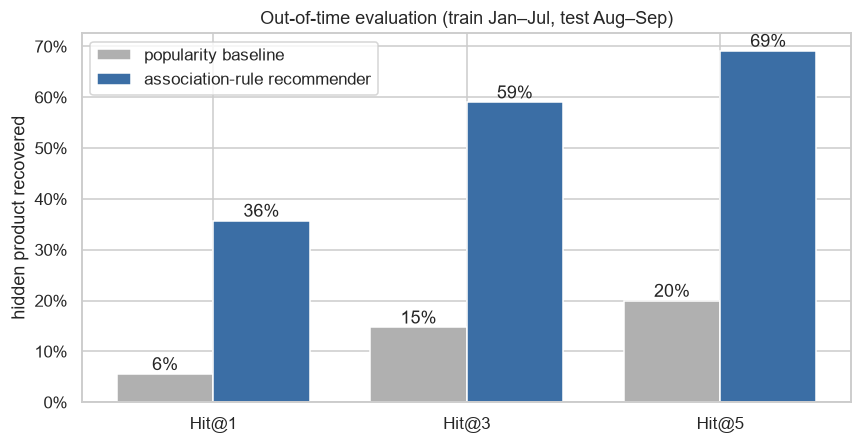

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = .38; x = np.arange(len(res))
b1 = ax.bar(x - w/2, res.popularity_hit_rate, w, label="popularity baseline", color="#b0b0b0")
b2 = ax.bar(x + w/2, res.rule_hit_rate, w, label="association-rule recommender", color="#3b6ea5")
ax.bar_label(b1, fmt="{:.0%}"); ax.bar_label(b2, fmt="{:.0%}")
ax.set_xticks(x, [f"Hit@{k}" for k in res.index]); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Out-of-time evaluation (train Jan–Jul, test Aug–Sep)", ylabel="hidden product recovered")
ax.legend(); plt.tight_layout(); plt.savefig("images/recommender_eval.png", bbox_inches="tight"); plt.show()

## 9. Cross-sell opportunity (AZN)
For each significant one-to-one rule whose consequent is an **OTC** product we count baskets that contained A but **not** B (the missed prompts), and assume that **8%** of them would accept a pharmacist prompt / POS suggestion (`basket.UPTAKE`) at an assumed **35% gross margin** (`basket.GROSS_MARGIN`). These are planning assumptions — the A/B test in the recommendations is how to replace them with measured numbers.

In [16]:
one = top_rules[(top_rules.antecedent.map(len) == 1) & (top_rules.consequent.map(len) == 1)].copy()
# both directions of a pair can be useful prompts; re-add the reverse rule if it is also strong
one = pd.concat([one, strong[(strong.antecedent.map(len) == 1) & (strong.consequent.map(len) == 1)]]).drop_duplicates("rule")
one["A"] = one.antecedent.str[0]; one["B"] = one.consequent.str[0]
one = one[~one.B.isin(RX)]
months = bk.month.nunique()
one["missed_per_month"] = (one.ant_support - one.support) * len(X) / months
price = dict(zip(products.product_id, products.list_price))
one["extra_revenue_month"] = one.missed_per_month * mb.UPTAKE * one.B.map(price)
one["extra_margin_month"] = one.extra_revenue_month * mb.GROSS_MARGIN
opp = (one.sort_values("extra_margin_month", ascending=False)
          .drop_duplicates("A")      # one prompt per trigger product at the till
          .head(10))
opp_tbl = opp[["rule", "confidence", "lift", "missed_per_month", "extra_revenue_month", "extra_margin_month"]]
print(f"Top-10 prompts: +AZN {opp.extra_revenue_month.sum():,.0f} revenue / +AZN {opp.extra_margin_month.sum():,.0f} gross margin per month "
      f"(≈ AZN {12 * opp.extra_margin_month.sum():,.0f} margin per year) — "
      f"{opp.extra_revenue_month.sum() / (bk.revenue.sum() / months):.1%} of monthly revenue")
opp_tbl

Top-10 prompts: +AZN 2,454 revenue / +AZN 859 gross margin per month (≈ AZN 10,305 margin per year) — 2.4% of monthly revenue


,rule,confidence,lift,missed_per_month,extra_revenue_month,extra_margin_month
47,Diapers → Infant formula,0.447,11.072,184.556,310.053,108.519
454,Throat lozenges → Vitamin C 1000,0.240,2.913,447.000,303.960,106.386
476,Paper tissues → Cold & flu powder,0.222,2.783,514.111,263.225,92.129
509,Paracetamol 500 → Cold & flu powder,0.211,2.641,495.778,253.838,88.843
37,Baby wipes → Infant formula,0.454,11.240,146.111,245.467,85.913
166,Amlodipine 5 → Magnesium B6,0.289,7.898,294.222,230.670,80.735
7,Metformin 850 → Glucose test strips,0.537,17.592,119.000,228.480,79.968
431,Nasal spray → Vitamin C 1000,0.269,3.265,313.000,212.840,74.494
31,Sunscreen SPF50 → After-sun gel,0.347,13.160,210.222,208.540,72.989
109,Eye drops → Contact lens solution,0.281,9.487,180.556,196.444,68.756


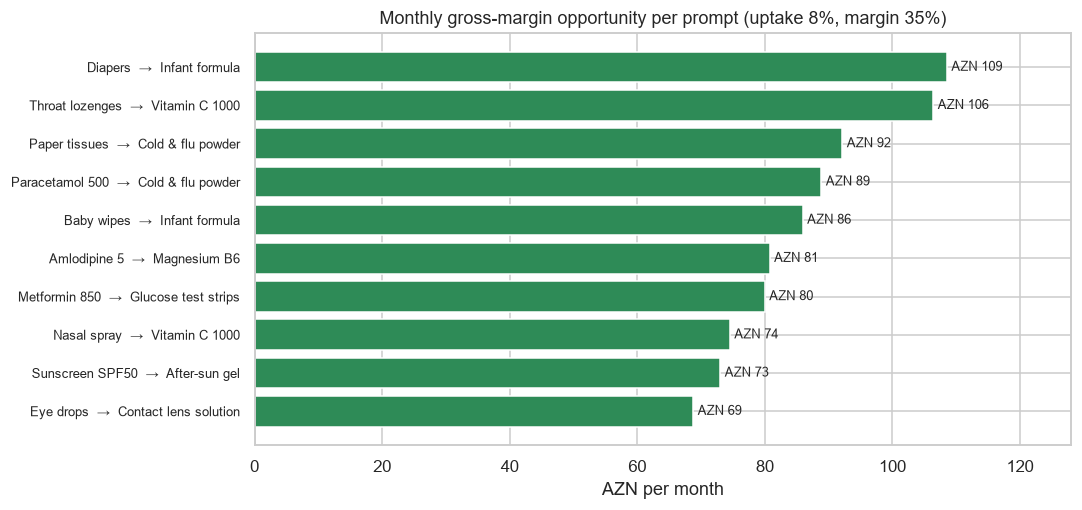

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.8))
o = opp.sort_values("extra_margin_month")
bars = ax.barh(o.rule, o.extra_margin_month, color="#2e8b57")
ax.bar_label(bars, fmt="AZN {:,.0f}", fontsize=8.5, padding=3)
ax.set(title=f"Monthly gross-margin opportunity per prompt (uptake {mb.UPTAKE:.0%}, margin {mb.GROSS_MARGIN:.0%})", xlabel="AZN per month")
ax.tick_params(axis="y", labelsize=8.5); ax.set_xlim(0, o.extra_margin_month.max() * 1.18)
plt.tight_layout(); plt.savefig("images/cross_sell_opportunity.png", bbox_inches="tight"); plt.show()

## 10. Findings & recommendations

In [18]:
def r(a, b):
    row = R[(R.antecedent == (a,)) & (R.consequent == (b,))].iloc[0]
    return row
ab = r("P12", "P14"); bp = r("P19", "P22"); cf = r("P01", "P02")
sub = neg.loc[neg.verdict == "substitute"]
seasonal = neg.loc[neg.verdict.str.startswith("seasonal")]
cfs = seas[seas.rule.str.startswith("Cold & flu powder")]
h3 = res.loc[3]
findings = pd.DataFrame([
 ("Basket size", f"{K['Single-item baskets']} of baskets hold a single product; ABV AZN {K['Average basket value, AZN']}",
  "Target single-item baskets with one scripted prompt at the till"),
 ("Significant rules", f"{len(strong)} of {len(R)} rules pass q<0.01, lift≥1.5, conf≥20% ({len(top_rules)} unique item sets)",
  "Only act on FDR-controlled rules; re-mine quarterly"),
 ("Cross-category bridge", f"Antibiotic (amoxicillin) → probiotic: confidence {ab.confidence:.0%}, lift {ab.lift:.1f}",
  "Pharmacist script: offer a probiotic with every antibiotic dispensed"),
 ("Chronic care", f"Amlodipine → Magnesium B6: confidence {bp.confidence:.0%}, lift {bp.lift:.1f}; diabetes trio lift ≈ {R.lift.max():.0f}",
  "Bundle 'monthly refill' packs (Rx + supplement/consumables) for loyalty members"),
 ("Seasonality", f"Cold & flu powder → lozenges: monthly confidence {cfs.confidence.min():.0%}–{cfs.confidence.max():.0%}, "
                 f"but support swings {cfs.support.max() / cfs.support.min():.0f}× (Jan vs summer)",
  "Keep the prompt list fixed, rotate endcaps: cold & flu (Nov–Mar), allergy (Apr–May), sun (Jun–Aug)"),
 ("Substitutes", f"{' ; '.join(sub.pair)}: stratified lift ≤ {sub.strat_lift.max():.2f} vs unrelated-pair baseline {BASE:.2f}",
  "Never cross-sell substitutes; shelve them side by side as a choice (generic vs brand)"),
 ("False 'substitutes'", f"{len(neg) - len(sub)} of the 10 most negative pairs are not substitutes: {len(seasonal)} season + small-basket effects, {len(neg) - len(sub) - len(seasonal)} different missions (e.g. {seasonal.pair.iloc[0]}: raw lift {seasonal.lift.iloc[0]:.2f} → stratified {seasonal.strat_lift.iloc[0]:.2f})",
  "Stratify by season and benchmark against unrelated pairs before calling products substitutes"),
 ("Recommender", f"Hit@3 {h3.rule_hit_rate:.0%} vs {h3.popularity_hit_rate:.0%} for best-sellers ({h3.uplift_x:.1f}×), out-of-time",
  "Deploy rule-based top-3 suggestions on the POS screen"),
 ("Money", f"Top-10 prompts ≈ AZN {opp.extra_margin_month.sum():,.0f} gross margin / month at {mb.UPTAKE:.0%} uptake",
  "A/B test prompts by store (3 vs 3 stores, 4 weeks) to measure real uptake before scaling"),
], columns=["Area", "Evidence", "Recommendation"])
pd.set_option("display.max_colwidth", None)
findings.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"})

Area,Evidence,Recommendation
Basket size,30.3% of baskets hold a single product; ABV AZN 19.58,Target single-item baskets with one scripted prompt at the till
Significant rules,"326 of 794 rules pass q<0.01, lift≥1.5, conf≥20% (144 unique item sets)",Only act on FDR-controlled rules; re-mine quarterly
Cross-category bridge,"Antibiotic (amoxicillin) → probiotic: confidence 54%, lift 9.7",Pharmacist script: offer a probiotic with every antibiotic dispensed
Chronic care,"Amlodipine → Magnesium B6: confidence 29%, lift 7.9; diabetes trio lift ≈ 18",Bundle 'monthly refill' packs (Rx + supplement/consumables) for loyalty members
Seasonality,"Cold & flu powder → lozenges: monthly confidence 45%–51%, but support swings 9× (Jan vs summer)","Keep the prompt list fixed, rotate endcaps: cold & flu (Nov–Mar), allergy (Apr–May), sun (Jun–Aug)"
Substitutes,Amoxicillin 500 × Azithromycin 500 ; Ibuprofen 400 × Metamizole 500: stratified lift ≤ 0.11 vs unrelated-pair baseline 0.51,Never cross-sell substitutes; shelve them side by side as a choice (generic vs brand)
False 'substitutes',"8 of the 10 most negative pairs are not substitutes: 6 season + small-basket effects, 2 different missions (e.g. Cough syrup × Insect repellent: raw lift 0.13 → stratified 0.36)",Stratify by season and benchmark against unrelated pairs before calling products substitutes
Recommender,"Hit@3 59% vs 15% for best-sellers (4.0×), out-of-time",Deploy rule-based top-3 suggestions on the POS screen
Money,Top-10 prompts ≈ AZN 859 gross margin / month at 8% uptake,"A/B test prompts by store (3 vs 3 stores, 4 weeks) to measure real uptake before scaling"


**Bottom line:** the chain's baskets are driven by clear customer missions. A short, statistically validated list of prompts — baby-care add-ons, cold & flu add-ons, chronic-care refills and antibiotic → probiotic — beats best-seller suggestions by a wide margin out-of-time, and should be rolled out through a controlled store-level A/B test so the uptake assumption is replaced by a measured number.